In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Collection

In [4]:
df = pd.read_csv(r"C:\Users\SAHU\OneDrive\Desktop\Data Analytic\Internship - IIM SKIlLS\Intership 30-10-2026\4th Project\car details v4.csv")

# Data Assessing

In [5]:
# Data Profiling
df.head()
df.tail()
df.shape
df.columns
df.describe()
df.describe(include = 'object')
df.info()

# For Null Values
df.isna().sum()[df.isna().sum()>0]
df.isnull().mean().mul(100).round(2)[df.isnull().mean().mul(100)>0]

# Outlier Detection Using IQR Method

COL = ['Price', 'KM Driven', 'Length', 'Width', 'Height', 'Fuel Tank Capacity']

for C in COL:
    Q1 = df[C].quantile(0.25)
    Q3 = df[C].quantile(0.75)
    IQR = Q3 - Q1
    LW = Q1 - 1.5 * IQR
    UW = Q3 + 1.5 * IQR

    print(C, ((df[C] < LW) | (df[C] > UW)).sum())
    print(C, LW)
    print(C, UW)

df[df['Price'] <= 0]
df[df['KM Driven'] <= 0]

# Inconsistence Data Format

col = ['Brand Name','Model','Fuel Type','Transmission','Location','Color','Owner','Seller Type','Drivetrain']

for c in col:
    print(df[c].value_counts())
    print('-'*50)

# For Duplicates

df[df.duplicated()]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Brand Name          2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   KM Driven           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

,Brand Name,Model,Price,Year,KM Driven,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity


### Data Profiling
- Reviewed the dataset structure, dimensions, column names, and data types.
- Examined numerical and categorical summaries to understand the data.
- Identified the overall structure of the used car dataset.

### Missing Value Assessment
- Identified columns containing missing values.
- Calculated missing-value percentages to assess data completeness.
- Noted missing values for further cleaning and treatment.

### Outlier Detection Using IQR
- Applied the IQR method to identify potential outliers in numerical columns.
- Calculated lower and upper limits for each selected column.
- Flagged unusual values for further investigation, not automatic removal.
- There is no sucn potential outliers found in the whole dataset, outliers which have been detected on those columns is not something which need to be worries because extreme values could be find in those type of columns.

### Invalid Value Assessment
- Checked for zero or negative values in Price and KM Driven.
- Identified potentially invalid records requiring further validation.
- There is no duplicated values in the dataset.

### Categorical Data Consistency
- Reviewed unique values across categorical columns.
- Checked for inconsistent spelling, capitalization, and formatting.
- There is no inconsistent values.

### Overall Conclusion
- Completed the initial data profiling and quality assessment.
- Identified missing values, and data-quality issues.
- The dataset is ready for the data-cleaning and preprocessing phase.

# Data Preprocessing

In [6]:
df.isna().mean().mul(100).round(2)[df.isna().mean().mul(100)>0]

Engine                3.89
Max Power             3.89
Max Torque            3.89
Drivetrain            6.61
Length                3.11
Width                 3.11
Height                3.11
Seating Capacity      3.11
Fuel Tank Capacity    5.49
dtype: float64

In [7]:
# Filling null values

# Columns containing missing values
cols = ['Engine', 'Max Power', 'Max Torque', 'Drivetrain',
        'Length', 'Width', 'Height', 'Seating Capacity',
        'Fuel Tank Capacity']

# Display missing values with their respective brands
for col in cols:
    print(f"\nMissing values in {col}:")
    display(df.loc[df[col].isnull(), ['Brand Name', col]])

# Object columns: Fill with brand-wise mode
mode_cols = ['Engine', 'Max Power', 'Max Torque', 'Drivetrain']

for col in mode_cols:
    df[col] = df[col].fillna(
        df.groupby('Brand Name')[col].transform(
            lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
        )
    )

# Numerical columns: Fill with brand-wise mean
mean_cols = ['Length', 'Width', 'Height', 'Seating Capacity',
             'Fuel Tank Capacity']

for col in mean_cols:
    df[col] = df[col].fillna(
        df.groupby('Brand Name')[col].transform('mean')
    )


Missing values in Engine:


,Brand Name,Engine
33,Honda,NaN
69,Audi,NaN
94,Mercedes-Benz,NaN
108,Honda,NaN
127,Tata,NaN
...,...,...
1906,MG,NaN
1928,Porsche,NaN
1980,Maruti Suzuki,NaN
2009,Audi,NaN



Missing values in Max Power:


,Brand Name,Max Power
33,Honda,NaN
69,Audi,NaN
94,Mercedes-Benz,NaN
108,Honda,NaN
127,Tata,NaN
...,...,...
1906,MG,NaN
1928,Porsche,NaN
1980,Maruti Suzuki,NaN
2009,Audi,NaN



Missing values in Max Torque:


,Brand Name,Max Torque
33,Honda,NaN
69,Audi,NaN
94,Mercedes-Benz,NaN
108,Honda,NaN
127,Tata,NaN
...,...,...
1906,MG,NaN
1928,Porsche,NaN
1980,Maruti Suzuki,NaN
2009,Audi,NaN


... (8 outputs left out)


Missing values in Seating Capacity:


,Brand Name,Seating Capacity
33,Honda,NaN
69,Audi,NaN
94,Mercedes-Benz,NaN
108,Honda,NaN
138,Maruti Suzuki,NaN
...,...,...
1898,Maruti Suzuki,NaN
1903,Hyundai,NaN
1928,Porsche,NaN
2009,Audi,NaN



Missing values in Fuel Tank Capacity:


,Brand Name,Fuel Tank Capacity
6,Mercedes-Benz,NaN
33,Honda,NaN
69,Audi,NaN
93,BMW,NaN
94,Mercedes-Benz,NaN
...,...,...
2017,Mahindra,NaN
2019,BMW,NaN
2025,Honda,NaN
2032,Land Rover,NaN


# Data Preprocessing and Data Cleaning

- These columns `'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity'` of dataset were containing the null values and null values percentage has been demostrated.

- Above syntax has been used for filling the null values in those columns, null vales in string datatype columns has been filled with the **Mode** of its respective Brand Name's value and null values in int/float datatype columns has been filled with the **Mean** values.

In [12]:
# Calculate car age
df['Car_Age'] = 2026 - df['Year']
display(df[['Year', 'Car_Age', 'Price']].head())

,Year,Car_Age,Price
0,2017,9,505000
1,2014,12,450000
2,2011,15,220000
3,2019,7,799000
4,2018,8,1950000


### Step 1: Feature Engineering – Car Age Calculation

**Objective:** Create a new feature named `Car_Age` to determine the age of each vehicle based on its manufacturing year.

**Operations Performed:**
- Used the existing `Year` column to calculate the age of each vehicle.
- Applied the formula: `Car_Age = 2026 - Year`.
- Created a new column named `Car_Age` in the DataFrame.
- This feature converts manufacturing years into a more interpretable numerical measure of vehicle age.

**Business Significance:**
- Helps analyse the relationship between vehicle age and resale price.
- Allows comparison of older and newer vehicles.
- Provides a useful variable for studying vehicle depreciation patterns.
- Can be used in further exploratory data analysis and predictive modelling.

**Conclusion:**
- Successfully created the `Car_Age` feature using the manufacturing year.
- Retained the available `Price` column without making unsupported assumptions.
- The newly created `Car_Age` feature is ready for further exploratory and business analysis.

In [13]:
# Calculate average car price for each transmission type

transmission_price = df.groupby('Transmission')['Price'].mean()

display(transmission_price)

Transmission
Automatic    2.979057e+06
Manual       6.600644e+05
Name: Price, dtype: float64

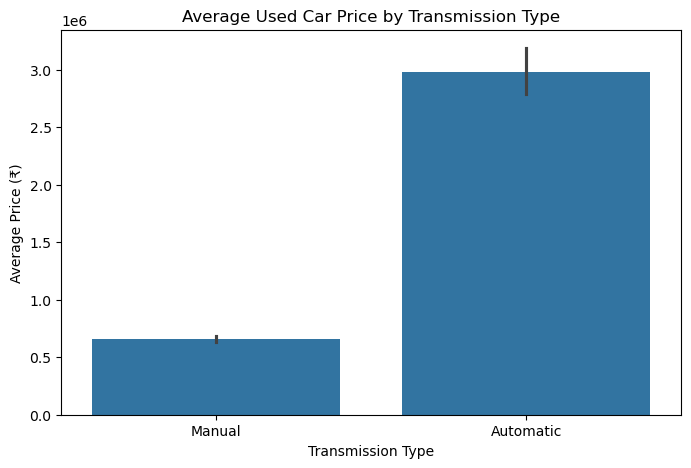

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='Transmission', y='Price')

plt.title('Average Used Car Price by Transmission Type')
plt.xlabel('Transmission Type')
plt.ylabel('Average Price (₹)')
plt.show()

In [15]:
# Identify transmission with the highest average price

print("Highest Average Price:",
      transmission_price.idxmax())

print("Average Price:",
      transmission_price.max())

Highest Average Price: Automatic
Average Price: 2979057.194384449


In [16]:
price_difference = transmission_price.max() - transmission_price.min()

print("Average Price Difference: ₹", round(price_difference, 2))

Average Price Difference: ₹ 2318992.82


### Step 2: Transmission Market Premiums – Bivariate Analysis

**Objective:** Analyse the relationship between transmission type and average used-car selling price to identify which transmission configuration commands a higher market price.

**Operations Performed:**
- Grouped the dataset using the `Transmission` column.
- Calculated the average vehicle price for each transmission category using the `Price` column.
- Created a Seaborn barplot to visually compare average prices across transmission types.
- Identified the transmission category with the highest average price.
- Calculated the average price difference between transmission categories.

**Key Analytical Observations:**
- Compared the average prices of manual and automatic transmission vehicles.
- Examined whether automatic transmission vehicles command a higher average price than manual transmission vehicles.
- Evaluated the price gap between different transmission configurations.

**Business Significance:**
- Helps understand customer preferences and pricing patterns across transmission categories.
- Identifies which transmission configuration is associated with higher resale prices.
- Supports used-car dealers in pricing strategies and inventory decisions.
- Helps identify potential market premiums associated with transmission type.

**Business Takeaway:**
- The transmission category with the highest average vehicle price represents the higher-priced segment in this dataset.
- A higher average price indicates a market price association, not necessarily a direct premium caused by transmission type.
- Brand, manufacturing year, mileage, vehicle specifications and other factors may also influence the observed price difference.

**Conclusion:**
- Successfully performed bivariate analysis between `Transmission` and `Price`.
- Compared average used-car prices across transmission categories.
- Identified the higher-priced transmission segment and its average price difference.
- Established a foundation for further investigation into the factors influencing used-car resale prices.

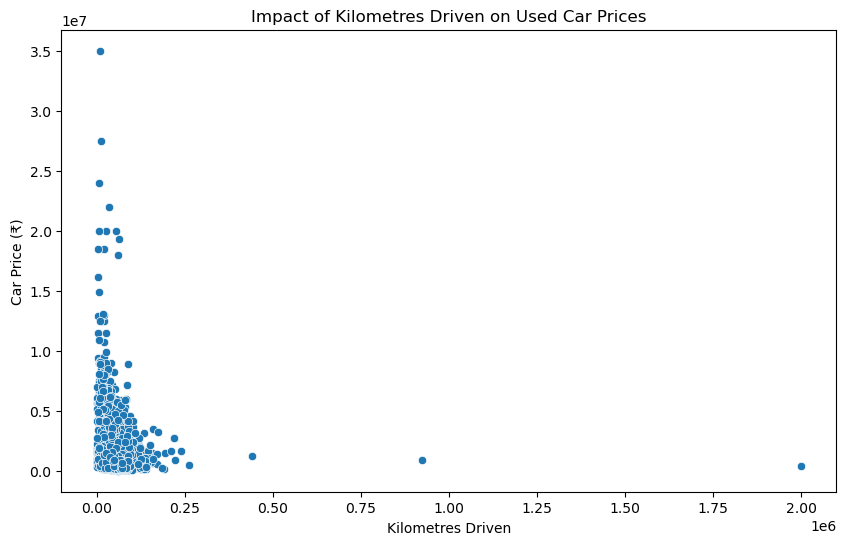

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='KM Driven', y='Price')

plt.title('Impact of Kilometres Driven on Used Car Prices')
plt.xlabel('Kilometres Driven')
plt.ylabel('Car Price (₹)')

plt.show()

In [18]:
correlation = df['KM Driven'].corr(df['Price'])

print("Correlation between KM Driven and Price:", round(correlation, 3))

Correlation between KM Driven and Price: -0.151


In [19]:
# Identify unusually high mileage and high-price vehicles

Q1 = df['KM Driven'].quantile(0.25)
Q3 = df['KM Driven'].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)

outliers = df[df['KM Driven'] > upper_limit]

display(outliers[['Brand Name', 'Year', 'KM Driven', 'Price']])

print("Total high-mileage outliers:", len(outliers))

,Brand Name,Year,KM Driven,Price
112,Toyota,2014,143000,1400000
134,BMW,2013,195000,1490000
181,Toyota,2014,211000,1675000
235,Porsche,2014,160000,3500000
249,Mahindra,2012,143000,549000
328,Maruti Suzuki,2017,140000,500000
388,Tata,2011,192326,199000
444,Mahindra,2015,157662,690000
477,Mercedes-Benz,2012,158000,1500000
628,Toyota,2013,170669,1450000


Total high-mileage outliers: 36


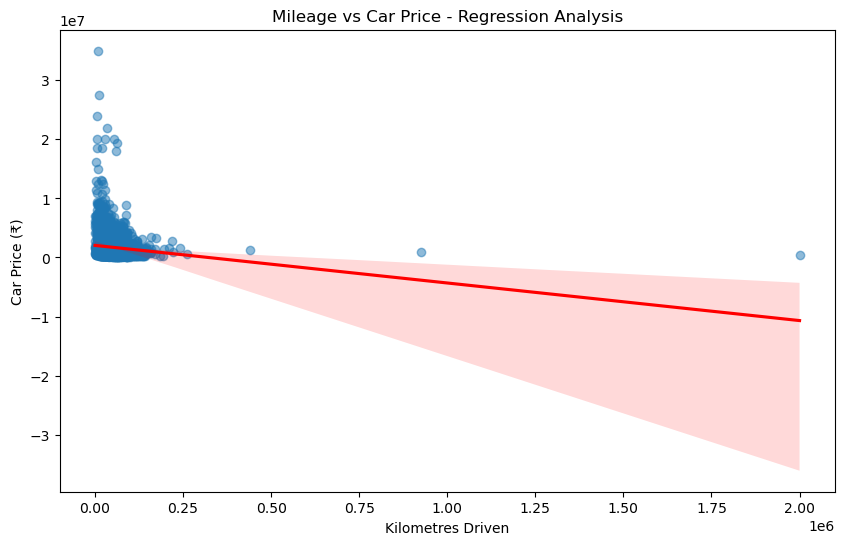

In [20]:
plt.figure(figsize=(10, 6))

sns.regplot(data=df, x='KM Driven', y='Price',
            scatter_kws={'alpha': 0.5},
            line_kws={'color': 'red'})

plt.title('Mileage vs Car Price - Regression Analysis')
plt.xlabel('Kilometres Driven')
plt.ylabel('Car Price (₹)')

plt.show()

### Step 3: Wear-and-Tear Analysis – Bivariate Analysis

**Objective:** Analyse the relationship between vehicle usage (kilometres driven) and its listed resale price to understand how accumulated mileage is associated with vehicle valuation.

**Operations Performed:**
- Created a Seaborn scatterplot using `KM Driven` on the X-axis and `Price` on the Y-axis.
- Examined the distribution and clustering of data points to identify mileage-related pricing patterns.
- Calculated the Pearson correlation coefficient to measure the direction and strength of the linear relationship between mileage and price.
- Applied the Interquartile Range (IQR) method to identify unusually high-mileage vehicles.
- Displayed potential outlier records along with their brand, manufacturing year, mileage and price.
- Created an additional regression plot to visualise the overall linear trend between vehicle mileage and listed price.

**Key Analytical Observations:**
- Examined whether vehicles with higher kilometres driven generally have lower listed prices.
- Evaluated the strength and direction of the correlation between mileage and price.
- Identified potential high-mileage outliers using the IQR method.
- Investigated whether certain high-mileage vehicles still maintain comparatively high listed prices.
- Observed the overall data distribution and regression trend to understand mileage-related pricing behaviour.

**Business Significance:**
- Helps understand the relationship between vehicle usage and resale valuation.
- Supports used-car dealers in evaluating vehicle pricing based on accumulated mileage.
- Helps identify unusually high-mileage vehicles that may require additional inspection.
- Provides useful insights for vehicle valuation, inventory assessment and purchasing decisions.

**Business Takeaway:**
- Higher mileage may be associated with lower resale prices because of increased vehicle usage and potential wear and tear.
- The correlation coefficient helps quantify the strength and direction of this relationship.
- High-mileage vehicles with unusually high listed prices may represent premium brands, models or vehicles with other valuable specifications.
- Mileage alone cannot determine a vehicle's resale value, as manufacturing year, brand, transmission and vehicle condition may also influence pricing.

**Conclusion:**
- Successfully performed bivariate analysis between `KM Driven` and `Price`.
- Evaluated the mileage–price relationship using scatterplot and correlation analysis.
- Identified potential high-mileage outliers using the IQR technique.
- Established a foundation for understanding how vehicle usage patterns are associated with used-car market prices.

**Note:** The identified outliers are statistical observations and should not automatically be considered incorrect data. Correlation indicates association rather than causation.

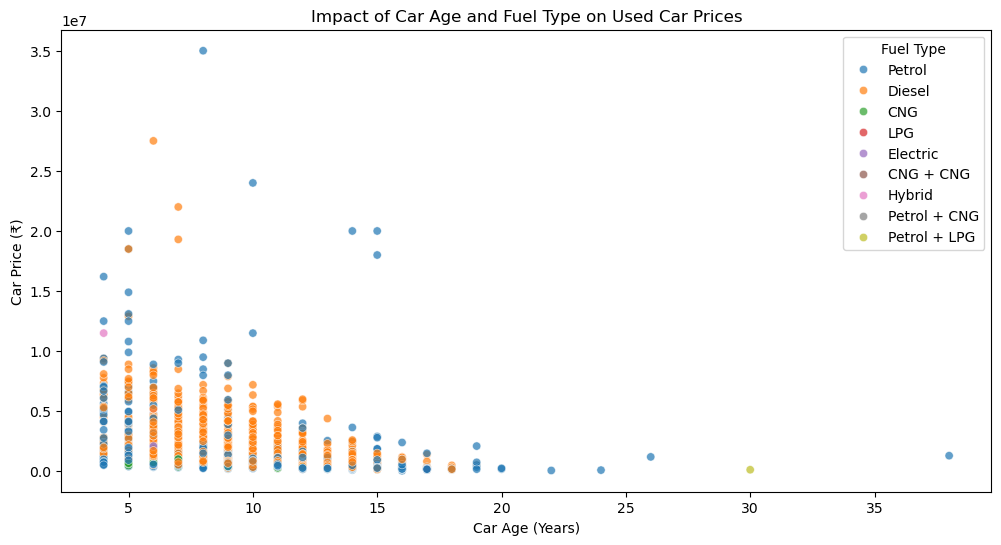

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x='Car_Age',
    y='Price',
    hue='Fuel Type',
    alpha=0.7
)

plt.title('Impact of Car Age and Fuel Type on Used Car Prices')
plt.xlabel('Car Age (Years)')
plt.ylabel('Car Price (₹)')
plt.legend(title='Fuel Type')

plt.show()

In [22]:
fuel_price = df.groupby('Fuel Type')['Price'].mean().sort_values(ascending=False)

display(fuel_price)

Fuel Type
Hybrid          7.166667e+06
Diesel          2.101848e+06
Electric        1.497857e+06
Petrol          1.322041e+06
Petrol + CNG    5.750000e+05
CNG             4.453800e+05
CNG + CNG       2.490000e+05
LPG             2.100000e+05
Petrol + LPG    1.300000e+05
Name: Price, dtype: float64

In [23]:
age_fuel_price = df.groupby(['Car_Age', 'Fuel Type'])['Price'].mean().reset_index()

display(age_fuel_price.head(10))

,Car_Age,Fuel Type,Price
0,4,CNG,6.100000e+05
1,4,Diesel,4.271103e+06
2,4,Electric,1.450000e+06
3,4,Hybrid,1.150000e+07
4,4,Petrol,3.286224e+06
5,5,CNG,6.885714e+05
6,5,Diesel,4.077293e+06
7,5,Electric,1.300000e+06
8,5,Petrol,2.994398e+06
9,6,CNG,7.175000e+05


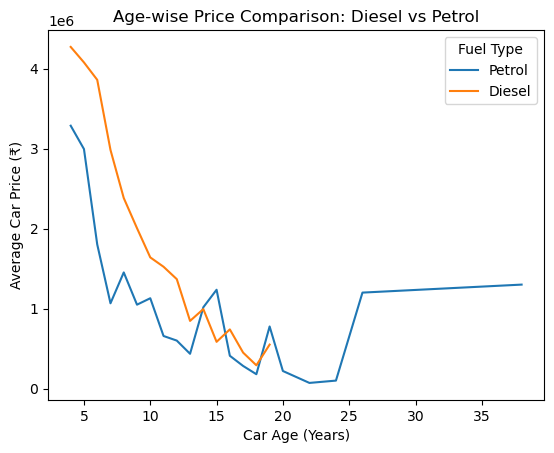

In [24]:
fuel_comparison = df[df['Fuel Type'].isin(['Diesel', 'Petrol'])]

sns.lineplot(
    data=fuel_comparison,
    x='Car_Age',
    y='Price',
    hue='Fuel Type',
    estimator='mean',
    errorbar=None
)

plt.title('Age-wise Price Comparison: Diesel vs Petrol')
plt.xlabel('Car Age (Years)')
plt.ylabel('Average Car Price (₹)')
plt.show()

# Fuel Economics Over Time – Multivariate Analysis

## 1. Objective
- Analyze the relationship between **Car Age, Fuel Type, and Used Car Price**.
- Understand how the average listed price of vehicles varies across different fuel types.
- Compare the age-wise price patterns of Diesel and Petrol vehicles.
- Identify whether fuel type and vehicle age are associated with differences in used-car pricing.

## 2. Operations Performed

- **Age and Fuel Type Comparison:** Used a scatter plot to visualize the relationship between Car Age and Price, with different colors representing fuel types.
- **Average Price by Fuel Type:** Grouped the dataset by Fuel Type and calculated the average listed price to compare different fuel categories.
- **Age-wise Fuel Analysis:** Grouped the data by Car Age and Fuel Type to examine how average prices vary across different vehicle age groups.
- **Diesel vs Petrol Comparison:** Filtered Diesel and Petrol vehicles and used a line plot to compare their average prices across different car ages.

## 3. Key Analytical Observations

- The scatter plot helps identify the distribution of vehicle prices across different age groups and fuel categories.
- The average price comparison highlights differences in listed prices among fuel types.
- The age-wise analysis helps examine whether the pricing gap between fuel categories changes as vehicles become older.
- The Diesel vs Petrol comparison provides a clearer view of how their average listed prices vary with vehicle age.
- Differences in price patterns may also be influenced by vehicle brand, model, manufacturing year, transmission, and other specifications.

## 4. Business Significance

- **Pricing Strategy:** Used-car dealers can evaluate how fuel type is associated with vehicle pricing.
- **Inventory Planning:** Dealers can compare the pricing patterns of different fuel categories when planning their vehicle inventory.
- **Customer Insights:** Buyers can use fuel-category comparisons as one factor when evaluating used vehicles.
- **Market Understanding:** Age-wise comparisons can help identify differences in the used-car market across fuel categories.

## 5. Business Takeaway

This analysis provides a comparative understanding of how vehicle age and fuel type are associated with used-car prices. It helps identify pricing patterns that can support used-car market analysis, inventory planning, and pricing decisions.

## 6. Conclusion

The analysis combines three variables — **Car Age, Fuel Type, and Price** — to understand their relationship in the used-car market. It provides a foundation for further multivariate analysis and helps identify patterns that may require deeper investigation.

**Important Note:** The dataset contains current used-car listed prices, not original purchase prices or historical resale prices. Therefore, this analysis identifies age-related pricing patterns rather than calculating actual vehicle depreciation. Also, average prices should be interpreted alongside the number of vehicles available in each age and fuel category.